# Projeto de Mineração de Dados
## Análise de Focos de Queimadas na Amazônia (2025)

**Disciplina:** Mineração de Dados  
**Equipe:** Deydson

## 1. Introdução

As queimadas são um grave problema ambiental no Brasil. Este trabalho analisa a base **BDQueimadas** (INPE/TerraBrasilis), com ~975 mil detecções de focos na região amazônica em 2025.

Objetivos:

- Identificar **onde** se concentram os focos → K-Means
- Descobrir **quais condições** geram focos mais intensos → Apriori

## 2. Justificativa

- **Relevância:** queimadas na Amazônia degradam floresta, emitem carbono e afetam a saúde da população.
- **Volume de dados:** ~1 milhão de registros, adequados para técnicas de mineração.
- **Aplicação:** os resultados podem apoiar ações de prevenção e fiscalização.

## 3. Revisão da Literatura

- **K-Means** (MacQueen, 1967): particiona os dados em $k$ grupos minimizando a variância interna. O valor de $k$ é definido pelo método do cotovelo e pelo coeficiente de silhueta (Kaufman & Rousseeuw, 1990).
- **Apriori** (Agrawal & Srikant, 1994): minera regras $X \Rightarrow Y$ em bases transacionais, avaliadas por **suporte**, **confiança** e **lift** (HAN; KAMBER; PEI, 2011).

## 4. Metodologia e Resultados

### 4.1 Base de Dados

Base **BDQueimadas** do INPE (TerraBrasilis): detecções de focos de queimada por satélite na região amazônica.

| Atributo | Descrição |
|---|---|
| `DataHora` | Data e hora da detecção |
| `Satelite` | Satélite (GOES-19, NOAA-20/21, NPP, AQUA, TERRA, METOP) |
| `Estado`, `Municipio` | Localização do foco |
| `Bioma` | Bioma (constante: Amazônia) |
| `DiaSemChuva` | Dias consecutivos sem chuva |
| `Precipitacao` | Precipitação acumulada (mm) |
| `RiscoFogo` | Índice de risco de fogo (0 a 1) |
| `FRP` | Potência radiativa (MW) — intensidade do foco |
| `Latitude`, `Longitude` | Coordenadas |

- **Volume:** 975.655 registros | **Período:** jan–dez/2025
- **Abrangência:** bioma Amazônia, 9 estados (PA, MT, AM, MA, RO, RR, AC, AP, TO)
- **Fonte:** [TerraBrasilis – BDQueimadas](https://terrabrasilis.dpi.inpe.br/queimadas/bdqueimadas/#mapa)

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

PATH = 'bdqueimadas_2025-01-01_2025-12-31.csv'
try:
    df = pd.read_csv(PATH, encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(PATH, encoding='latin-1')

df['DataHora'] = pd.to_datetime(df['DataHora'], format='%Y/%m/%d %H:%M:%S')
df.head()

,DataHora,Satelite,Pais,Estado,Municipio,Bioma,DiaSemChuva,Precipitacao,RiscoFogo,FRP,Latitude,Longitude
0,2025-01-01 00:00:00,GOES-16,Brasil,MATO GROSSO,VILA BELA DA SANTÍSSIMA TRINDADE,Amazônia,3.0,1.97,0.63,84.8,-15.2530,-60.2095
1,2025-01-01 00:00:00,GOES-16,Brasil,MATO GROSSO,VILA BELA DA SANTÍSSIMA TRINDADE,Amazônia,3.0,1.86,0.31,89.1,-15.2723,-60.2078
2,2025-01-01 00:10:00,GOES-16,Brasil,MATO GROSSO,VILA BELA DA SANTÍSSIMA TRINDADE,Amazônia,3.0,1.97,0.63,76.1,-15.2530,-60.2095
3,2025-01-01 00:10:00,GOES-16,Brasil,MATO GROSSO,VILA BELA DA SANTÍSSIMA TRINDADE,Amazônia,3.0,1.86,0.31,90.6,-15.2723,-60.2078
4,2025-01-01 00:20:00,GOES-16,Brasil,MATO GROSSO,VILA BELA DA SANTÍSSIMA TRINDADE,Amazônia,3.0,1.97,0.63,62.9,-15.2530,-60.2095


In [33]:
print('Shape:', df.shape)
print('\nValores nulos por atributo:')
print(df.isna().sum())
print('\nAtributos categóricos:')
for col in ['Satelite', 'Pais', 'Estado', 'Bioma']:
    print(f'\n{col}: {df[col].nunique()} valores únicos')
    print(df[col].value_counts().head(10))

Shape: (975655, 12)

Valores nulos por atributo:
DataHora            0
Satelite            0
Pais                0
Estado              0
Municipio           0
Bioma               0
DiaSemChuva     25596
Precipitacao    25596
RiscoFogo       25596
FRP             15101
Latitude            0
Longitude           0
dtype: int64

Atributos categóricos:

Satelite: 13 valores únicos
Satelite
GOES-19      227128
NOAA-20      220050
NOAA-21      217530
NPP-375      152762
NPP-375D      68735
AQUA_M-T      43131
TERRA_M-M     13683
METOP-B        8127
TERRA_M-T      7965
METOP-C        6933
Name: count, dtype: int64

Pais: 1 valores únicos
Pais
Brasil    975655
Name: count, dtype: int64

Estado: 9 valores únicos
Estado
PARÁ           332780
MATO GROSSO    230034
AMAZONAS       142928
MARANHÃO        93533
RONDÔNIA        58204
RORAIMA         44508
ACRE            44255
AMAPÁ           18905
TOCANTINS       10508
Name: count, dtype: int64

Bioma: 1 valores únicos
Bioma
Amazônia    975655
Name: c

### 4.2 Pré-processamento

1. **Conversão de `DataHora`** para `datetime` e extração do mês (`Mes`).
2. **Tratamento de ausências:** o código `-999` (valor sentinela do INPE) foi substituído por NaN e as variáveis climáticas preenchidas com a mediana; `FRP` ausente assumido como 0.
3. **Log em `FRP`** (`log1p`), pois a variável é assimétrica e tem valores extremos.
4. **Discretização** dos atributos contínuos em faixas — necessária porque o Apriori trabalha com itens discretos.
5. **Padronização (z-score)** para o K-Means, igualando a contribuição de cada variável.
6. **Amostra de 200 mil registros** para as regras de associação, por viabilidade computacional.

In [34]:
# Cópia de trabalho e engenharia de atributos
dfp = df.copy()
dfp['Mes'] = dfp['DataHora'].dt.month

# -999 é o código de "sem dado" do INPE -> trata como ausente
dfp[['DiaSemChuva', 'RiscoFogo']] = dfp[['DiaSemChuva', 'RiscoFogo']].replace(-999, np.nan)

# Ausências: mediana para variáveis climáticas; FRP ausente = 0
dfp[['DiaSemChuva', 'Precipitacao', 'RiscoFogo']] = dfp[['DiaSemChuva', 'Precipitacao', 'RiscoFogo']].fillna(
    dfp[['DiaSemChuva', 'Precipitacao', 'RiscoFogo']].median())
dfp['FRP'] = dfp['FRP'].fillna(0)
dfp['FRP_log'] = np.log1p(dfp['FRP'])

# Discretização para regras de associação
dfp['DiaSemChuva_cat'] = pd.cut(dfp['DiaSemChuva'], bins=[0, 3, 7, 15, 999],
                               labels=['0-3 dias', '4-7 dias', '8-15 dias', '>15 dias'])
dfp['Precipitacao_cat'] = pd.cut(dfp['Precipitacao'], bins=[-0.01, 0, 1, 5, 20, 9999],
                                 labels=['Sem chuva', '0-1mm', '1-5mm', '5-20mm', '>20mm'])
dfp['RiscoFogo_cat'] = pd.cut(dfp['RiscoFogo'], bins=[-0.01, 0.25, 0.5, 0.75, 1.01],
                             labels=['Baixo', 'Medio', 'Alto', 'Muito alto'])
dfp['FRP_cat'] = pd.cut(dfp['FRP'], bins=[-0.01, 20, 100, 500, 1e9],
                        labels=['FRP_Baixo', 'FRP_Moderado', 'FRP_Alto', 'FRP_Muito alto'])

print(dfp[['Mes', 'FRP_log', 'DiaSemChuva_cat', 'Precipitacao_cat', 'RiscoFogo_cat', 'FRP_cat']].describe(include='all'))
print('\nDistribuição de FRP por faixa:')
print(dfp['FRP_cat'].value_counts())

                  Mes        FRP_log DiaSemChuva_cat Precipitacao_cat  \
count   975655.000000  975655.000000          866718           975655   
unique            NaN            NaN               4                5   
top               NaN            NaN        4-7 dias        Sem chuva   
freq              NaN            NaN          276441           705448   
mean         8.735911       2.650551             NaN              NaN   
std          2.251367       1.436224             NaN              NaN   
min          1.000000       0.000000             NaN              NaN   
25%          8.000000       1.568616             NaN              NaN   
50%          9.000000       2.351375             NaN              NaN   
75%         10.000000       4.003690             NaN              NaN   
max         12.000000       8.434855             NaN              NaN   

       RiscoFogo_cat    FRP_cat  
count         975655     975655  
unique             4          4  
top       Muito alto 

### 4.3 Agrupamento de Dados

**Objetivo:** encontrar hotspots de focos de queimada na região amazônica.

**Dados:** `Latitude`, `Longitude`, `FRP_log`, `DiaSemChuva` e `RiscoFogo`, padronizados (z-score).

**Algoritmo:** **K-Means** — eficiente em bases grandes e fácil de interpretar.

**Escolha de $k$:** método do cotovelo + coeficiente de silhueta.

**Avaliação:** tamanho dos clusters, FRP médio e composição por estado.

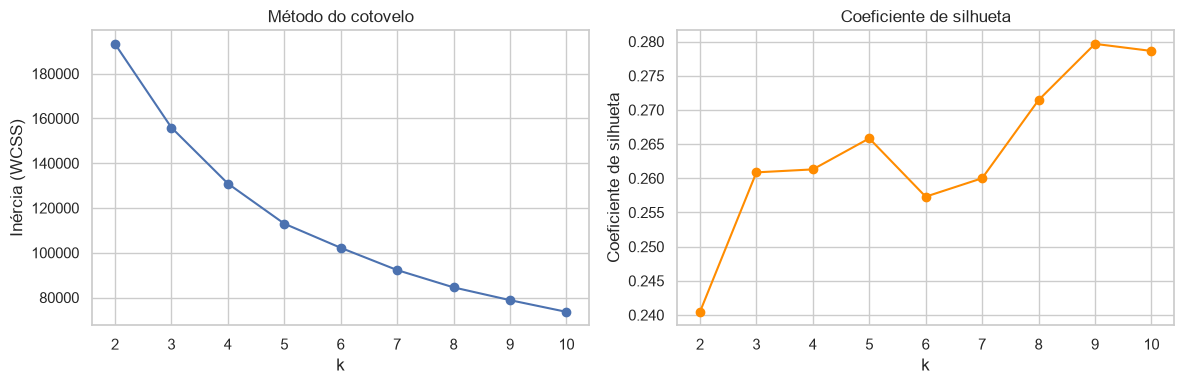

k=2: silhueta=0.2405
k=3: silhueta=0.2609
k=4: silhueta=0.2613
k=5: silhueta=0.2658
k=6: silhueta=0.2573
k=7: silhueta=0.2600
k=8: silhueta=0.2714
k=9: silhueta=0.2797
k=10: silhueta=0.2786


In [35]:
# Preparação dos dados para o K-Means
features_cluster = ['Latitude', 'Longitude', 'FRP_log', 'DiaSemChuva', 'RiscoFogo']
X = dfp[features_cluster].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Cotovelo + silhueta em amostra (silhueta é custosa em bases grandes)
amostra_idx = np.random.RandomState(42).choice(len(X_scaled), size=min(50000, len(X_scaled)), replace=False)
X_amostra = X_scaled[amostra_idx]

inertias, silhouettes = [], []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_amostra)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_amostra, km.labels_, sample_size=20000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2, 11), inertias, marker='o')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inércia (WCSS)'); axes[0].set_title('Método do cotovelo')
axes[1].plot(range(2, 11), silhouettes, marker='o', color='darkorange')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Coeficiente de silhueta'); axes[1].set_title('Coeficiente de silhueta')
plt.tight_layout(); plt.show()

for k, s in zip(range(2, 11), silhouettes):
    print(f'k={k}: silhueta={s:.4f}')

In [36]:
# Número de clusters escolhido pelo cotovelo/silhueta (ajuste se necessário)
K = 5

km_final = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
dfp['Cluster'] = km_final.labels_

resumo = dfp.groupby('Cluster').agg(
    n=('Cluster', 'size'),
    lat_media=('Latitude', 'mean'),
    lon_media=('Longitude', 'mean'),
    frp_medio=('FRP', 'mean'),
    frp_mediano=('FRP', 'median'),
    dias_sem_chuva=('DiaSemChuva', 'mean'),
    risco_fogo=('RiscoFogo', 'mean'),
).round(2)
resumo['pct'] = (resumo['n'] / resumo['n'].sum() * 100).round(2)
resumo.sort_values('n', ascending=False)

,n,lat_media,lon_media,frp_medio,frp_mediano,dias_sem_chuva,risco_fogo,pct
Cluster,,,,,,,,
3,283268,-2.96,-49.80,27.38,8.2,7.21,0.87,29.03
1,222843,-9.62,-62.18,6.61,5.0,6.67,0.60,22.84
4,199991,-3.12,-54.13,16.29,6.9,2.62,0.19,20.50
0,176453,-8.90,-59.27,121.82,84.9,8.34,0.69,18.09
2,93100,-10.31,-53.29,46.92,13.5,40.76,0.93,9.54


In [37]:
# Composição dos clusters por estado (top 3 por cluster)
for c in sorted(dfp['Cluster'].unique()):
    sub = dfp[dfp['Cluster'] == c]
    print(f'\n=== Cluster {c} ({len(sub):,} focos) ===')
    print('Estados:', sub['Estado'].value_counts().head(3).to_dict())


=== Cluster 0 (176,453 focos) ===
Estados: {'MATO GROSSO': 71115, 'AMAZONAS': 52538, 'PARÁ': 23702}

=== Cluster 1 (222,843 focos) ===
Estados: {'MATO GROSSO': 84790, 'AMAZONAS': 56238, 'ACRE': 38993}

=== Cluster 2 (93,100 focos) ===
Estados: {'MATO GROSSO': 64318, 'PARÁ': 20257, 'MARANHÃO': 3623}

=== Cluster 3 (283,268 focos) ===
Estados: {'PARÁ': 156671, 'MARANHÃO': 82887, 'RORAIMA': 21302}

=== Cluster 4 (199,991 focos) ===
Estados: {'PARÁ': 125133, 'AMAZONAS': 32059, 'RORAIMA': 22305}


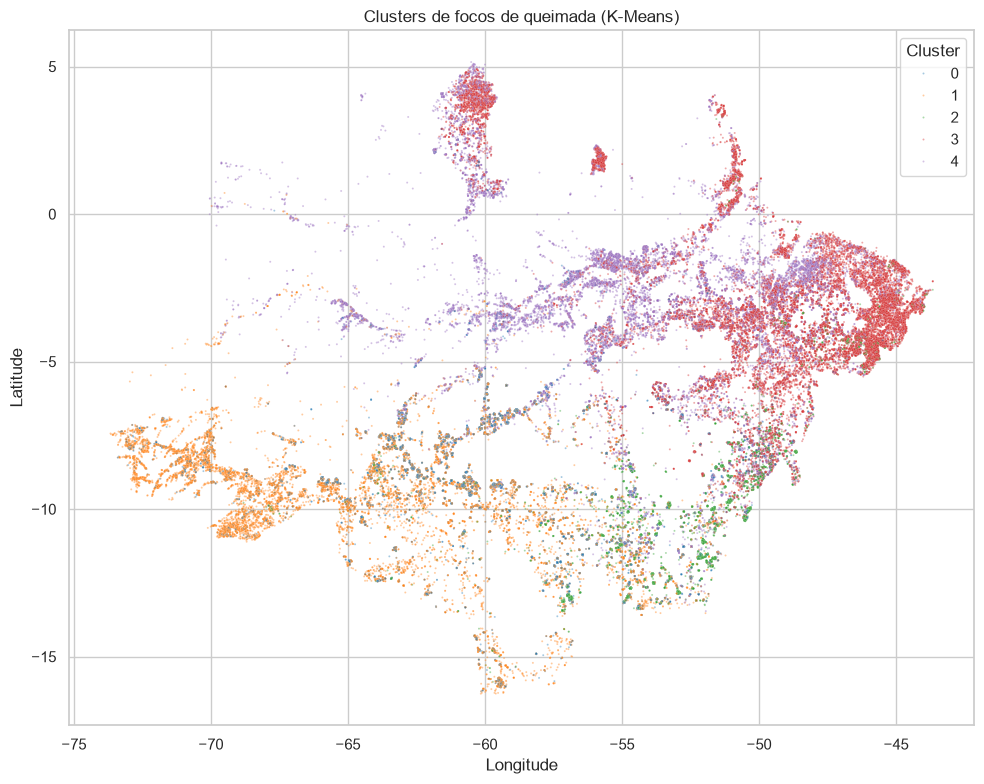

In [38]:
# Mapa dos clusters (amostra para performance)
amostra_plot = dfp.sample(n=min(100000, len(dfp)), random_state=42)
plt.figure(figsize=(10, 8))
sns.scatterplot(data=amostra_plot, x='Longitude', y='Latitude',
                hue='Cluster', palette='tab10', s=2, alpha=0.4, legend='full')
plt.title('Clusters de focos de queimada (K-Means)')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.tight_layout(); plt.show()

**Interpretação:** o K-Means separou os focos em 5 grupos:

- **Cluster 0** (18%): Mato Grosso/Amazonas (lat −8,9, lon −59,3) — **maior intensidade** (FRP médio ~122), região do arco do desmatamento.
- **Cluster 1** (23%): sul do Amazonas/norte de MT e RO — muitos focos, porém baixa intensidade (FRP ~7).
- **Cluster 2** (9,5%): sul de Mato Grosso — **maior risco** (0,93) e média de ~41 dias sem chuva; fronteira agrícola.
- **Cluster 3** (29%): nordeste do Pará — maior número de focos (283 mil), risco alto (0,87).
- **Cluster 4** (20%): norte do Pará — poucos dias sem chuva (2,6) e menor risco (0,19); região mais úmida.

### 4.4 Regras de Associação

**Objetivo:** descobrir quais condições (estado, mês, clima) se associam a focos mais intensos.

**Dados:** `Estado`, `Mes`, `DiaSemChuva_cat`, `Precipitacao_cat`, `RiscoFogo_cat` e `FRP_cat` — cada registro vira uma transação de itens (ex.: `Mes=8`, `Sem chuva`). `Bioma` foi descartado por ser constante.

**Algoritmo:** **Apriori** (Agrawal & Srikant, 1994) via `mlxtend`, amostra de 200 mil registros.

**Avaliação:** suporte ≥ 1%, confiança ≥ 20% e **lift > 1.2**.

In [39]:
try:
    import mlxtend
except ImportError:
    get_ipython().system('pip install mlxtend')

from mlxtend.frequent_patterns import apriori, association_rules

# Cada registro vira uma transação de itens 'ATRIBUTO=valor'
cols_item = ['Estado', 'Mes', 'DiaSemChuva_cat',
             'Precipitacao_cat', 'RiscoFogo_cat', 'FRP_cat']

df_am = dfp[cols_item].sample(n=min(200000, len(dfp)), random_state=42)

itens_cols = {}
for c in cols_item:
    s = df_am[c].astype(str)
    for v in s.unique():
        itens_cols[f'{c}={v}'] = (s == v).values
X_itens = pd.DataFrame(itens_cols, index=df_am.index).astype(bool)

print('Dimensão da matriz de transações:', X_itens.shape)

Dimensão da matriz de transações: (200000, 39)


In [40]:
# Itemsets frequentes e regras
freq_itemsets = apriori(X_itens, min_support=0.01, use_colnames=True)
freq_itemsets['length'] = freq_itemsets['itemsets'].apply(len)
print('Itemsets frequentes:', len(freq_itemsets))

regras = association_rules(freq_itemsets, metric='confidence', min_threshold=0.2)
regras = regras[regras['lift'] > 1.2].sort_values('lift', ascending=False)
print('Regras com lift > 1.2:', len(regras))

cols_regras = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
regras[cols_regras].head(20)

Itemsets frequentes: 1133
Regras com lift > 1.2: 2734


,antecedents,consequents,support,confidence,lift
915,"frozenset({Mes=1, Precipitacao_cat=Sem chuva})",frozenset({Estado=RORAIMA}),0.012050,0.872556,18.900815
918,frozenset({Estado=RORAIMA}),"frozenset({Mes=1, Precipitacao_cat=Sem chuva})",0.012050,0.261020,18.900815
93,frozenset({Estado=RORAIMA}),frozenset({Mes=3}),0.010485,0.227120,17.437245
94,frozenset({Mes=3}),frozenset({Estado=RORAIMA}),0.010485,0.804990,17.437245
916,"frozenset({Estado=RORAIMA, Precipitacao_cat=Se...",frozenset({Mes=1}),0.012050,0.348921,13.940127
917,frozenset({Mes=1}),"frozenset({Estado=RORAIMA, Precipitacao_cat=Se...",0.012050,0.481422,13.940127
91,frozenset({Mes=1}),frozenset({Estado=RORAIMA}),0.015095,0.603076,13.063496
92,frozenset({Estado=RORAIMA}),frozenset({Mes=1}),0.015095,0.326979,13.063496
921,"frozenset({FRP_cat=FRP_Baixo, Estado=RORAIMA})",frozenset({Mes=1}),0.010690,0.310215,12.393717
922,frozenset({Mes=1}),"frozenset({FRP_cat=FRP_Baixo, Estado=RORAIMA})",0.010690,0.427087,12.393717


In [41]:
# Exibe regras de forma legível (sem frozensets)
def tem_item(consequents, padroes):
    return consequents.apply(lambda s: any(p in i for i in s for p in padroes))

def mostrar(df_r, titulo, n=10):
    d = df_r[cols_regras].head(n).copy()
    d['antecedentes'] = d['antecedents'].apply(lambda s: ' & '.join(sorted(s)))
    d['consequentes'] = d['consequents'].apply(lambda s: ' & '.join(sorted(s)))
    d = d[['antecedentes', 'consequentes', 'support', 'confidence', 'lift']].round(3)
    print(f'\n=== {titulo} ({len(df_r)} regras) ===')
    print(d.to_string(index=False))

# Regras -> focos intensos (FRP moderado ou superior)
frp_intenso = regras[tem_item(regras['consequents'],
                   ['FRP_cat=FRP_Moderado', 'FRP_cat=FRP_Alto', 'FRP_cat=FRP_Muito alto'])]
mostrar(frp_intenso, 'Regras -> FRP moderado/alto (top 10 por lift)', 10)

# Regras -> risco de fogo alto
fogo_alto = regras[tem_item(regras['consequents'], ['RiscoFogo_cat=Alto', 'RiscoFogo_cat=Muito alto'])]
mostrar(fogo_alto, 'Regras -> risco de fogo alto (top 10 por lift)', 10)


=== Regras -> FRP moderado/alto (top 10 por lift) (122 regras) ===
                                                           antecedentes                                                           consequentes  support  confidence  lift
                                             Mes=8 & RiscoFogo_cat=Alto                                 Estado=AMAZONAS & FRP_cat=FRP_Moderado    0.010       0.208 5.093
                                                                  Mes=6 Estado=MATO GROSSO & FRP_cat=FRP_Moderado & Precipitacao_cat=Sem chuva    0.013       0.229 4.037
                             Estado=AMAZONAS & RiscoFogo_cat=Muito alto                                           FRP_cat=FRP_Moderado & Mes=8    0.011       0.287 4.030
DiaSemChuva_cat=4-7 dias & Estado=AMAZONAS & Precipitacao_cat=Sem chuva                                           FRP_cat=FRP_Moderado & Mes=8    0.010       0.279 3.929
                                     Mes=6 & Precipitacao_cat=Sem chuva           

**Interpretação:** as regras mais fortes ligam **falta de chuva + meses de estação seca** a focos intensos e risco alto. Exemplos:

- `4–7 dias sem chuva & Amazonas & Sem chuva → mês 8 & risco alto`: confiança 0,44, **lift 8,7**
- `mês 7 & Sem chuva → >15 dias sem chuva & risco alto`: confiança 0,21, lift 8,2
- `MT & >15 dias sem chuva & mês 8 → risco muito alto`: confiança 0,71, lift 5,9
- `mês 8 & risco alto → FRP moderado no Amazonas`: confiança 0,21, lift 5,1

Ou seja: focos no **Amazonas em agosto** e no **sul de Mato Grosso na seca** têm risco e intensidade muito acima do esperado.

## 5. Conclusão

Aplicamos K-Means e Apriori à BDQueimadas (Amazônia, 2025). O agrupamento identificou 5 hotspots: o mais intenso fica na região MT/Amazonas (FRP médio ~122), enquanto o sul de MT concentra o maior risco de fogo associado a longos períodos sem chuva. As regras de associação confirmam que **seca prolongada + meses de estiagem (jun–ago)** geram focos mais intensos — resultado coerente com os alertas do INPE.

**Limitações:** clusters esféricos do K-Means, $k$ fixo e faixas de discretização manuais. Futuro: DBSCAN, dados de uso do solo e comparação entre anos.

## 6. Referências

AGRAWAL, R.; SRIKANT, R. Fast algorithms for mining association rules. In: **Proceedings of the 20th International Conference on Very Large Data Bases (VLDB)**, 1994. p. 487–499.

HAN, J.; KAMBER, M.; PEI, J. **Data mining: concepts and techniques**. 3. ed. Boston: Morgan Kaufmann, 2011.

INSTITUTO NACIONAL DE PESQUISAS ESPACIAIS (INPE). **BDQueimadas: base de dados de queimadas**. TerraBrasilis. Disponível em: <https://terrabrasilis.dpi.inpe.br/queimadas/bdqueimadas/#mapa>. Acesso em: 18 nov. 2025.

KAUFMAN, L.; ROUSSEEUW, P. J. **Finding groups in data: an introduction to cluster analysis**. New York: Wiley, 1990.

MACQUEEN, J. B. Some methods for classification and analysis of multivariate observations. In: **Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability**, 1967. p. 281–297.